Używane urządzenie: cuda
Trening: Baseline...
Trening: Wariant 1 (Augmentacja)...
Trening: Wariant 2 (BatchNorm + Dropout)...
Trening: Wariant strojony (kombinacja)...

--- ZESTAWIENIE DO TABELI W SPRAWOZDANIU ---
Baseline (brak ulepszeń)            | Epoka:  7 | Val Acc: 89.13% | Luka: 0.1072
Wariant 1 (Augmentacja)             | Epoka: 12 | Val Acc: 83.35% | Luka: 0.0203
Wariant 2 (BatchNorm + Dropout 0.3) | Epoka: 11 | Val Acc: 89.24% | Luka: 0.0947
Wariant strojony (kombinacja)       | Epoka: 12 | Val Acc: 82.36% | Luka: 0.0136

Luka generalizacji (Baseline): 0.1072
Luka generalizacji (Strojony): 0.0136
Końcowe Accuracy Testowe (Baseline): 88.29%
Końcowe Accuracy Testowe (Strojony): 81.60%


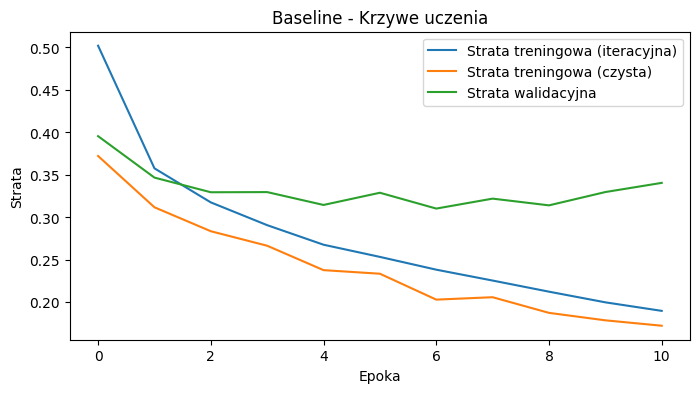

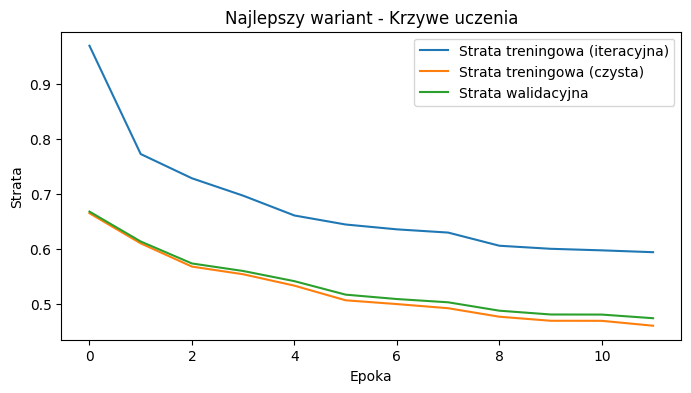


Badanie wpływu Learning Rate...
lr=0.1     -> val accuracy: 20.07%
lr=0.01    -> val accuracy: 86.75%
lr=0.001   -> val accuracy: 88.32%
lr=0.0001  -> val accuracy: 85.64%


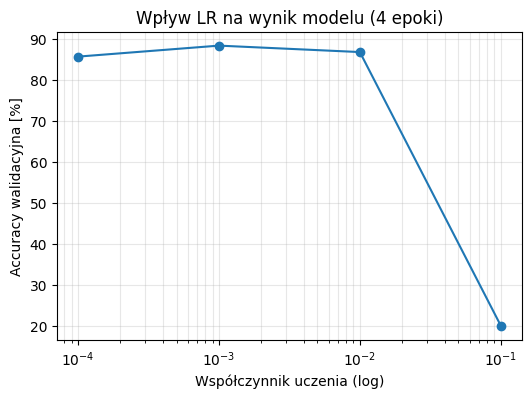

In [3]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import copy

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Używane urządzenie:", device)

mean, std = 0.2860, 0.3530
test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])
train_tf_plain = test_tf
train_tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(28, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])

full_train_plain = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=train_tf_plain)
full_train_aug = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=train_tf_aug)
test_ds = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=test_tf)

indices = list(range(60000))
train_idx, val_idx = indices[:50000], indices[50000:]

train_plain_ds = Subset(full_train_plain, train_idx)
train_aug_ds = Subset(full_train_aug, train_idx)
val_ds = Subset(full_train_plain, val_idx)

train_plain_dl = DataLoader(train_plain_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
train_aug_dl = DataLoader(train_aug_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
train_eval_dl = DataLoader(train_plain_ds, batch_size=512, shuffle=False, num_workers=2, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=512, shuffle=False, num_workers=2, pin_memory=True)
test_dl = DataLoader(test_ds, batch_size=512, shuffle=False, num_workers=2, pin_memory=True)

class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10, use_bn=False, p_drop=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum / total, correct / total

def run_training(model, train_dl, train_eval_dl, val_dl, epochs=12, lr=1e-3, weight_decay=0.0, use_scheduler=False, patience=4):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs//3), gamma=0.5) if use_scheduler else None

    hist = {"train_loss": [], "train_eval_loss": [], "val_loss": [], "val_acc": []}
    best_val_loss = float('inf')
    best_model_wts = copy.deepcopy(model.state_dict())
    best_epoch = 1
    epochs_no_improve = 0

    for epoch in range(1, epochs + 1):
        model.train()
        run = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item() * yb.numel()
        if sched:
            sched.step()

        tr = run / len(train_dl.dataset)
        tr_eval, _ = evaluate(model, train_eval_dl)
        val_loss, val_acc = evaluate(model, val_dl)

        hist["train_loss"].append(tr)
        hist["train_eval_loss"].append(tr_eval)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_model_wts = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            break

    model.load_state_dict(best_model_wts)
    return hist, best_epoch

epochs_budget = 12

print("Trening: Baseline...")
base_model = MLP(use_bn=False, p_drop=0.0)
hist_base, epoch_base = run_training(base_model, train_plain_dl, train_eval_dl, val_dl, epochs=epochs_budget)
test_loss_base, test_acc_base = evaluate(base_model, test_dl)

print("Trening: Wariant 1 (Augmentacja)...")
aug_model = MLP(use_bn=False, p_drop=0.0)
hist_aug, epoch_aug = run_training(aug_model, train_aug_dl, train_eval_dl, val_dl, epochs=epochs_budget)

print("Trening: Wariant 2 (BatchNorm + Dropout)...")
bn_drop_model = MLP(use_bn=True, p_drop=0.3)
hist_bn_drop, epoch_bn_drop = run_training(bn_drop_model, train_plain_dl, train_eval_dl, val_dl, epochs=epochs_budget)

print("Trening: Wariant strojony (kombinacja)...")
tuned_model = MLP(use_bn=True, p_drop=0.3)
hist_tuned, epoch_tuned = run_training(tuned_model, train_aug_dl, train_eval_dl, val_dl, epochs=epochs_budget, weight_decay=1e-4, use_scheduler=True)
test_loss_tuned, test_acc_tuned = evaluate(tuned_model, test_dl)

print("\n--- ZESTAWIENIE DO TABELI W SPRAWOZDANIU ---")
def print_row(name, hist, epoch):
    val_acc = hist["val_acc"][epoch - 1] * 100
    gap = hist["val_loss"][epoch - 1] - hist["train_eval_loss"][epoch - 1]
    print(f"{name:35s} | Epoka: {epoch:2d} | Val Acc: {val_acc:.2f}% | Luka: {gap:.4f}")

print_row("Baseline (brak ulepszeń)", hist_base, epoch_base)
print_row("Wariant 1 (Augmentacja)", hist_aug, epoch_aug)
print_row("Wariant 2 (BatchNorm + Dropout 0.3)", hist_bn_drop, epoch_bn_drop)
print_row("Wariant strojony (kombinacja)", hist_tuned, epoch_tuned)

gap_base = hist_base["val_loss"][epoch_base - 1] - hist_base["train_eval_loss"][epoch_base - 1]
gap_tuned = hist_tuned["val_loss"][epoch_tuned - 1] - hist_tuned["train_eval_loss"][epoch_tuned - 1]

print(f"\nLuka generalizacji (Baseline): {gap_base:.4f}")
print(f"Luka generalizacji (Strojony): {gap_tuned:.4f}")
print(f"Końcowe Accuracy Testowe (Baseline): {test_acc_base * 100:.2f}%")
print(f"Końcowe Accuracy Testowe (Strojony): {test_acc_tuned * 100:.2f}%")

def plot_curves(hist, title):
    plt.figure(figsize=(8, 4))
    plt.plot(hist["train_loss"], label="Strata treningowa (iteracyjna)")
    plt.plot(hist["train_eval_loss"], label="Strata treningowa (czysta)")
    plt.plot(hist["val_loss"], label="Strata walidacyjna")
    plt.title(title)
    plt.xlabel("Epoka")
    plt.ylabel("Strata")
    plt.legend()
    plt.show()

plot_curves(hist_base, "Baseline - Krzywe uczenia")
plot_curves(hist_tuned, "Najlepszy wariant - Krzywe uczenia")

print("\nBadanie wpływu Learning Rate...")
lrs = [1e-1, 1e-2, 1e-3, 1e-4]
acc_by_lr = []
for lr in lrs:
    m = MLP()
    h, _ = run_training(m, train_plain_dl, train_eval_dl, val_dl, epochs=4, lr=lr)
    acc_by_lr.append(max(h["val_acc"]))
    print(f"lr={lr:<7} -> val accuracy: {max(h['val_acc'])*100:.2f}%")

plt.figure(figsize=(6, 4))
plt.semilogx(lrs, [a * 100 for a in acc_by_lr], "o-")
plt.xlabel("Współczynnik uczenia (log)")
plt.ylabel("Accuracy walidacyjna [%]")
plt.title("Wpływ LR na wynik modelu (4 epoki)")
plt.grid(True, which="both", alpha=0.3)
plt.show()